# Лабораторна робота № 8
## Методи кластеризації: K-Means, метод ліктя, коефіцієнт силуета та PCA

**Мета:** навчитися застосовувати алгоритм K-Means, добирати кількість кластерів за допомогою методу ліктя та коефіцієнта силуета; дослідити використання PCA. Додатково — порівняти моделі класифікації на наборі даних про студентів (цей етап збережено з початкової роботи).

**Середовище:** Google Colab або Jupyter Notebook із Python. Для завдання 2 потрібно завантажити набір даних з кагл https://www.kaggle.com/datasets/rabieelkharoua/students-performance-dataset?select=Student_performance_data+_.csv.

**Виконання:** запускайте комірки послідовно, зверху вниз.

## Завдання 1. Кластеризація набору даних Iris

**1.1. Імпорт бібліотек.** Імпортуйте `matplotlib`, `pandas`, `seaborn`, `load_iris`, `KMeans`, `silhouette_score` і `StandardScaler`.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler


**1.2. Завантаження Iris.** Завантажте Iris та виведіть перші п’ять рядків таблиці з назвами ознак.

In [2]:
# Завантаження набору Iris та перегляд перших п’яти рядків
iris = load_iris()
# Для подальших пунктів використовуємо ті самі три ознаки Iris.
iris_df = pd.DataFrame(iris.data[:, :3], columns=iris.feature_names[:3])

print("Розмір набору даних:", iris_df.shape)
display(iris_df.head())


Розмір набору даних: (150, 3)


,sepal length (cm),sepal width (cm),petal length (cm)
0,5.1,3.5,1.4
1,4.9,3.0,1.4
2,4.7,3.2,1.3
3,4.6,3.1,1.5
4,5.0,3.6,1.4


**1.3. Масштабування та метод ліктя.** Стандартизуйте дані та за допомогою методу ліктя визначте оптимальну кількість кластерів

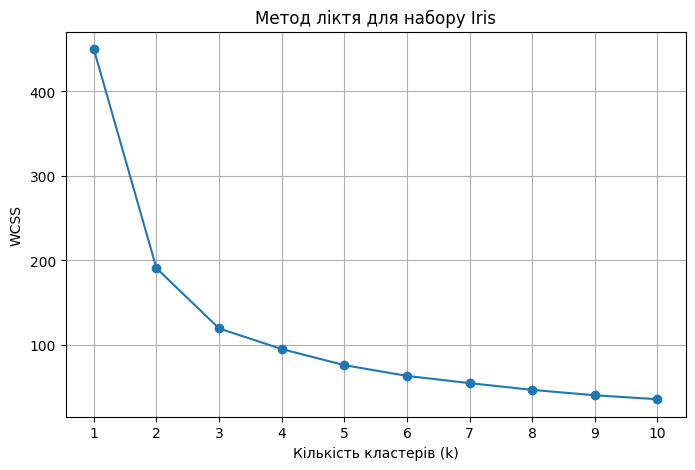

Значення WCSS:
k=1: 450.000
k=2: 190.469
k=3: 119.139
k=4: 94.641
k=5: 75.628
k=6: 62.870
k=7: 54.282
k=8: 46.313
k=9: 39.890
k=10: 35.226


In [3]:
# Стандартизація ознак та метод ліктя
scaler_iris = StandardScaler()
X_iris_scaled = scaler_iris.fit_transform(iris_df)

wcss_iris = []
k_values_iris = range(1, 11)
for k in k_values_iris:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_iris_scaled)
    wcss_iris.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(list(k_values_iris), wcss_iris, marker='o')
plt.title('Метод ліктя для набору Iris')
plt.xlabel('Кількість кластерів (k)')
plt.ylabel('WCSS')
plt.xticks(list(k_values_iris))
plt.grid(True)
plt.show()

print("Значення WCSS:")
for k, value in zip(k_values_iris, wcss_iris):
    print(f"k={k}: {value:.3f}")


**1.4. Метод силуетів.** Для тих самих трьох ознак Iris обчисліть середній коефіцієнт силуета для 2–10 кластерів і побудуйте графік.

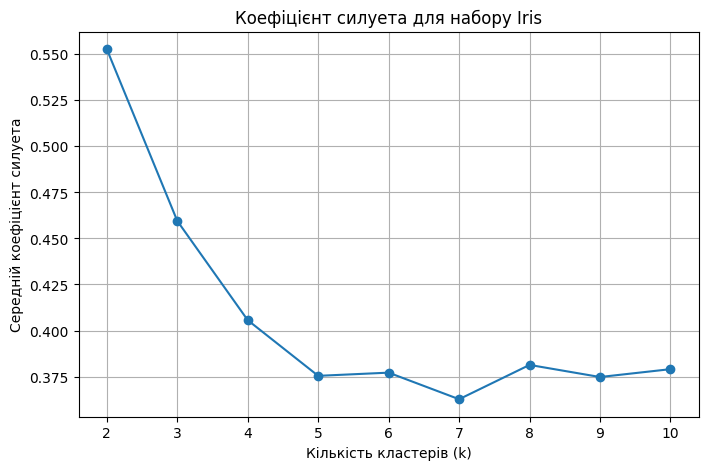

Найбільший коефіцієнт силуета отримано для k=2: 0.5525


In [4]:
# Середній коефіцієнт силуета для 2–10 кластерів
silhouette_values_iris = []
k_values_silhouette_iris = range(2, 11)

for k in k_values_silhouette_iris:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_iris_scaled)
    score = silhouette_score(X_iris_scaled, labels)
    silhouette_values_iris.append(score)

plt.figure(figsize=(8, 5))
plt.plot(list(k_values_silhouette_iris), silhouette_values_iris, marker='o')
plt.title('Коефіцієнт силуета для набору Iris')
plt.xlabel('Кількість кластерів (k)')
plt.ylabel('Середній коефіцієнт силуета')
plt.xticks(list(k_values_silhouette_iris))
plt.grid(True)
plt.show()

best_silhouette_k_iris = list(k_values_silhouette_iris)[int(max(range(len(silhouette_values_iris)), key=silhouette_values_iris.__getitem__))]
print(f"Найбільший коефіцієнт силуета отримано для k={best_silhouette_k_iris}: {max(silhouette_values_iris):.4f}")


**1.5. Фінальна кластеризація та візуалізація.** Побудуйте K-Means для `n_clusters=2`  На площині покажіть перші дві з них та відповідні координати центрів. Це **двовимірне відображення результату кластеризації за трьома ознаками**.

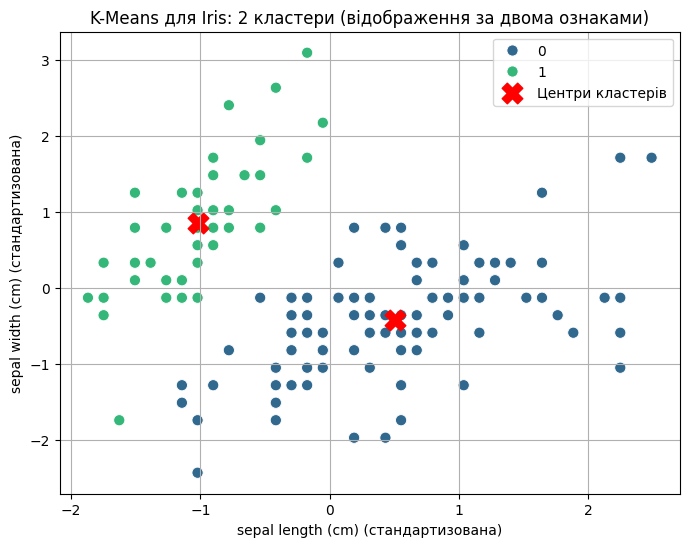

Кількість об’єктів у кластерах:
0    100
1     50
Name: count, dtype: int64
Координати центрів у просторі трьох ознак:
[[ 0.50728948 -0.42663134  0.65249366]
 [-1.01457897  0.85326268 -1.30498732]]


In [5]:
# Фінальна кластеризація для n_clusters=2 та двовимірна візуалізація
kmeans_iris_final = KMeans(n_clusters=2, random_state=42, n_init=10)
iris_clusters = kmeans_iris_final.fit_predict(X_iris_scaled)

# Для графіка використовуємо перші дві стандартизовані ознаки,
# а сама модель кластеризації навчається на всіх трьох ознаках.
plt.figure(figsize=(8, 6))
sns.scatterplot(
    x=X_iris_scaled[:, 0], y=X_iris_scaled[:, 1],
    hue=iris_clusters, palette='viridis', s=65
)
centers_2d = kmeans_iris_final.cluster_centers_[:, :2]
plt.scatter(centers_2d[:, 0], centers_2d[:, 1],
            c='red', marker='X', s=220, label='Центри кластерів')
plt.title('K-Means для Iris: 2 кластери (відображення за двома ознаками)')
plt.xlabel(iris.feature_names[0] + ' (стандартизована)')
plt.ylabel(iris.feature_names[1] + ' (стандартизована)')
plt.legend()
plt.grid(True)
plt.show()

print("Кількість об’єктів у кластерах:")
print(pd.Series(iris_clusters).value_counts().sort_index())
print("Координати центрів у просторі трьох ознак:")
print(kmeans_iris_final.cluster_centers_)


**Короткий висновок до завдання 1:** порівняйте результати методу ліктя й методу силуетів. Поясніть, чому обрано два кластери та чи збігається такий вибір з отриманими графіками.

**Висновок**

За методом ліктя найбільше зменшення WCSS спостерігається під час переходу від одного до двох кластерів, а далі зниження стає менш різким. Найвище середнє значення коефіцієнта силуета для перевірених варіантів також отримано при двох кластерах (приблизно 0,5525). Тому вибір `n_clusters=2` узгоджується з обома способами оцінювання: два кластери дають помітне розділення об’єктів і не ускладнюють модель зайвими групами.


## Завдання 2. Дослідження даних студентів

Спочатку порівняйте три класифікатори (як у початковій лабораторній роботі), а потім виконайте кластеризацію. **Класифікація та кластеризація — різні задачі:** у класифікації використовується цільова ознака `GradeClass`, а в кластеризації — ні.

**2.1. Імпорт бібліотек для класифікації.** Імпортуйте засоби для поділу даних, добору параметрів, класифікації та оцінювання моделей.

In [6]:
import pandas as pd
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report
import os

# Цей імпорт доступний у Google Colab; у звичайному Jupyter він не обов’язковий.
try:
    from google.colab import files
except ImportError:
    files = None


**2.2. Завантаження файлу.** Помістіть `Student_data.csv` до робочої папки або завантажте його через Colab. Файл містить дані з Вашої початкової роботи.

In [7]:
# Завантаження офіційного набору даних із Kaggle
%pip -q install kagglehub
import kagglehub

path = kagglehub.dataset_download("rabieelkharoua/students-performance-dataset")
print("Path to dataset files:", path)


100%|██████████| 66.2k/66.2k [00:00<00:00, 11.3MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/rabieelkharoua/students-performance-dataset/versions/2


**2.3. Перегляд даних.** Прочитайте CSV у DataFrame і перегляньте вміст.

In [8]:
# Зчитування CSV-файлу з каталогу, який повернув kagglehub
import glob
csv_candidates = glob.glob(os.path.join(path, '**', 'Student_performance_data *.csv'), recursive=True)
if not csv_candidates:
    csv_candidates = glob.glob(os.path.join(path, '**', '*.csv'), recursive=True)
if not csv_candidates:
    raise FileNotFoundError("У завантаженому наборі не знайдено CSV-файл Student_performance_data.")

csv_path = next((p for p in csv_candidates if 'Student_performance_data' in os.path.basename(p)), csv_candidates[0])
df = pd.read_csv(csv_path)
print("Завантажений файл:", csv_path)
print("Розмір таблиці:", df.shape)
display(df.head())


Завантажений файл: /root/.cache/kagglehub/datasets/rabieelkharoua/students-performance-dataset/versions/2/Student_performance_data _.csv
Розмір таблиці: (2392, 15)


,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
0,1001,17,1,0,2,19.833723,7,1,2,0,0,1,0,2.929196,2.0
1,1002,18,0,0,1,15.408756,0,0,1,0,0,0,0,3.042915,1.0
2,1003,15,0,2,3,4.210570,26,0,2,0,0,0,0,0.112602,4.0
3,1004,17,1,0,3,10.028829,14,0,3,1,0,0,0,2.054218,3.0
4,1005,17,1,0,2,4.672495,17,1,3,0,0,0,0,1.288061,4.0


**2.4. Назви стовпців.** Виведіть назви всіх стовпців.

In [9]:
# Виведення назв усіх стовпців
print("Назви стовпців набору даних:")
for column in df.columns:
    print(column)


Назви стовпців набору даних:
StudentID
Age
Gender
Ethnicity
ParentalEducation
StudyTimeWeekly
Absences
Tutoring
ParentalSupport
Extracurricular
Sports
Music
Volunteering
GPA
GradeClass


**2.5. Структура таблиці.** Перегляньте типи стовпців і кількість непорожніх значень.

In [10]:
# Інформація про структуру таблиці та типи даних
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2392 entries, 0 to 2391
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   StudentID          2392 non-null   int64  
 1   Age                2392 non-null   int64  
 2   Gender             2392 non-null   int64  
 3   Ethnicity          2392 non-null   int64  
 4   ParentalEducation  2392 non-null   int64  
 5   StudyTimeWeekly    2392 non-null   float64
 6   Absences           2392 non-null   int64  
 7   Tutoring           2392 non-null   int64  
 8   ParentalSupport    2392 non-null   int64  
 9   Extracurricular    2392 non-null   int64  
 10  Sports             2392 non-null   int64  
 11  Music              2392 non-null   int64  
 12  Volunteering       2392 non-null   int64  
 13  GPA                2392 non-null   float64
 14  GradeClass         2392 non-null   float64
dtypes: float64(3), int64(12)
memory usage: 280.4 KB


**2.6. Пропущені значення.** Перевірте, чи містить набір даних пропущені значення.

In [11]:
# Перевірка пропущених значень
missing_values = df.isnull().sum()
print("Кількість пропущених значень у кожному стовпці:")
print(missing_values)
print("Загальна кількість пропущених значень:", int(missing_values.sum()))


Кількість пропущених значень у кожному стовпці:
StudentID            0
Age                  0
Gender               0
Ethnicity            0
ParentalEducation    0
StudyTimeWeekly      0
Absences             0
Tutoring             0
ParentalSupport      0
Extracurricular      0
Sports               0
Music                0
Volunteering         0
GPA                  0
GradeClass           0
dtype: int64
Загальна кількість пропущених значень: 0


**2.7. Дублікати.** Обчисліть кількість дублікатів.

In [12]:
# Підрахунок дублікатів
print("Кількість повністю дубльованих рядків:", int(df.duplicated().sum()))


Кількість повністю дубльованих рядків: 0


**2.8. Описова статистика.** Виведіть основні описові статистики.

In [13]:
# Основні описові статистики
display(df.describe(include='all').T)


,count,mean,std,min,25%,50%,75%,max
StudentID,2392.0,2196.500000,690.655244,1001.000000,1598.750000,2196.500000,2794.250000,3392.000000
Age,2392.0,16.468645,1.123798,15.000000,15.000000,16.000000,17.000000,18.000000
Gender,2392.0,0.510870,0.499986,0.000000,0.000000,1.000000,1.000000,1.000000
Ethnicity,2392.0,0.877508,1.028476,0.000000,0.000000,0.000000,2.000000,3.000000
ParentalEducation,2392.0,1.746237,1.000411,0.000000,1.000000,2.000000,2.000000,4.000000
StudyTimeWeekly,2392.0,9.771992,5.652774,0.001057,5.043079,9.705363,14.408410,19.978094
Absences,2392.0,14.541388,8.467417,0.000000,7.000000,15.000000,22.000000,29.000000
Tutoring,2392.0,0.301421,0.458971,0.000000,0.000000,0.000000,1.000000,1.000000
ParentalSupport,2392.0,2.122074,1.122813,0.000000,1.000000,2.000000,3.000000,4.000000
Extracurricular,2392.0,0.383361,0.486307,0.000000,0.000000,0.000000,1.000000,1.000000


**2.9. Підготовка даних для класифікації.** Сформуйте `X` та `y`, прибравши з ознак цільову змінну `GradeClass` і службовий ідентифікатор `StudentID`. Поділіть дані у співвідношенні 80/20 та стандартизуйте ознаки.

In [14]:
# Формування ознак X та цільової змінної y
# StudentID є ідентифікатором, тому не використовується як ознака.
X = df.drop(columns=['GradeClass', 'StudentID'])
y = df['GradeClass']

# Поділ 80/20 зі збереженням пропорцій класів
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Стандартизація: scaler навчається лише на тренувальних даних
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Розмір X_train:", X_train.shape)
print("Розмір X_test:", X_test.shape)
print("Розмір y_train:", y_train.shape)
print("Розмір y_test:", y_test.shape)


Розмір X_train: (1913, 13)
Розмір X_test: (479, 13)
Розмір y_train: (1913,)
Розмір y_test: (479,)


### 2.10. Класифікація: Random Forest

**Модель Random Forest.** Здійсніть добір гіперпараметрів `GridSearchCV` (5 згорток), виведіть найкращі параметри, середню CV-точність і тестову accuracy. Пошук може тривати довше через велику сітку параметрів.

In [15]:
# Добір гіперпараметрів Random Forest (5-fold CV)
rf_param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [None, 10],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2]
}
rf_grid = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid=rf_param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    verbose=1
)
rf_grid.fit(X_train_scaled, y_train)
rf_best = rf_grid.best_estimator_
rf_test_accuracy = accuracy_score(y_test, rf_best.predict(X_test_scaled))
print("Найкращі параметри Random Forest:", rf_grid.best_params_)
print(f"Середня CV-точність: {rf_grid.best_score_:.4f}")
print(f"Тестова accuracy: {rf_test_accuracy:.4f}")


Fitting 5 folds for each of 16 candidates, totalling 80 fits
Найкращі параметри Random Forest: {'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 200}
Середня CV-точність: 0.9211
Тестова accuracy: 0.9102


### 2.11. Класифікація: Logistic Regression

**Модель Logistic Regression.** Застосуйте `GridSearchCV` до логістичної регресії. Для багатокласової задачі використайте `saga` — `liblinear` у нових версіях sklearn не підтримує багатокласову класифікацію без додаткової обгортки.

In [16]:
# Добір гіперпараметрів Logistic Regression (5-fold CV)
logreg_param_grid = {
    'C': [0.1, 1, 10],
    'penalty': ['l2'],
    'solver': ['saga'],
    'max_iter': [5000],
    'class_weight': [None, 'balanced']
}
logreg_grid = GridSearchCV(
    LogisticRegression(random_state=42),
    param_grid=logreg_param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    verbose=1
)
logreg_grid.fit(X_train_scaled, y_train)
logreg_best = logreg_grid.best_estimator_
logreg_test_accuracy = accuracy_score(y_test, logreg_best.predict(X_test_scaled))
print("Найкращі параметри Logistic Regression:", logreg_grid.best_params_)
print(f"Середня CV-точність: {logreg_grid.best_score_:.4f}")
print(f"Тестова accuracy: {logreg_test_accuracy:.4f}")


Fitting 5 folds for each of 6 candidates, totalling 30 fits
Найкращі параметри Logistic Regression: {'C': 10, 'class_weight': None, 'max_iter': 5000, 'penalty': 'l2', 'solver': 'saga'}
Середня CV-точність: 0.7951
Тестова accuracy: 0.7933


### 2.12. Класифікація: Support Vector Machine

**Модель SVM.** Виконайте підбір параметрів SVM та обчисліть CV-точність і тестову accuracy.

In [17]:
# Добір гіперпараметрів Support Vector Machine (5-fold CV)
svm_param_grid = {
    'C': [0.1, 1, 10],
    'kernel': ['linear', 'rbf'],
    'gamma': ['scale', 'auto']
}
svm_grid = GridSearchCV(
    SVC(),
    param_grid=svm_param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    verbose=1
)
svm_grid.fit(X_train_scaled, y_train)
svm_best = svm_grid.best_estimator_
svm_test_accuracy = accuracy_score(y_test, svm_best.predict(X_test_scaled))
print("Найкращі параметри SVM:", svm_grid.best_params_)
print(f"Середня CV-точність: {svm_grid.best_score_:.4f}")
print(f"Тестова accuracy: {svm_test_accuracy:.4f}")


Fitting 5 folds for each of 12 candidates, totalling 60 fits
Найкращі параметри SVM: {'C': 10, 'gamma': 'scale', 'kernel': 'linear'}
Середня CV-точність: 0.8521
Тестова accuracy: 0.8580


### 2.13. Порівняння результатів

**Порівняння моделей.** Порівняйте тестову точність трьох моделей. Оберіть модель **за найкращою CV-точністю**, а звіт `classification_report` виведіть один раз на тестових даних.

In [18]:
# Порівняння трьох класифікаторів за CV-точністю та тестовою accuracy
classification_results = pd.DataFrame({
    'Модель': ['Random Forest', 'Logistic Regression', 'SVM'],
    'CV accuracy': [rf_grid.best_score_, logreg_grid.best_score_, svm_grid.best_score_],
    'Test accuracy': [rf_test_accuracy, logreg_test_accuracy, svm_test_accuracy]
})
classification_results = classification_results.sort_values('CV accuracy', ascending=False).reset_index(drop=True)
display(classification_results)

best_model_name = classification_results.loc[0, 'Модель']
best_model = {
    'Random Forest': rf_best,
    'Logistic Regression': logreg_best,
    'SVM': svm_best
}[best_model_name]
print("Модель, обрана за найкращою CV-точністю:", best_model_name)
print("Classification report для обраної моделі:")
print(classification_report(y_test, best_model.predict(X_test_scaled), zero_division=0))


,Модель,CV accuracy,Test accuracy
0,Random Forest,0.921071,0.910230
1,SVM,0.852065,0.858038
2,Logistic Regression,0.795084,0.793319


Модель, обрана за найкращою CV-точністю: Random Forest
Classification report для обраної моделі:
              precision    recall  f1-score   support

         0.0       1.00      0.29      0.44        21
         1.0       0.82      0.85      0.84        54
         2.0       0.89      0.95      0.92        78
         3.0       0.89      0.89      0.89        83
         4.0       0.94      0.97      0.96       243

    accuracy                           0.91       479
   macro avg       0.91      0.79      0.81       479
weighted avg       0.91      0.91      0.90       479



### 2.14. Кластеризація даних студентів: метод ліктя

**Метод ліктя для студентів.** Для кластеризації використайте чотири числові ознаки `Age`, `StudyTimeWeekly`, `Absences`, `GPA`. Стандартизуйте їх і побудуйте графік WCSS для 1–10 кластерів.

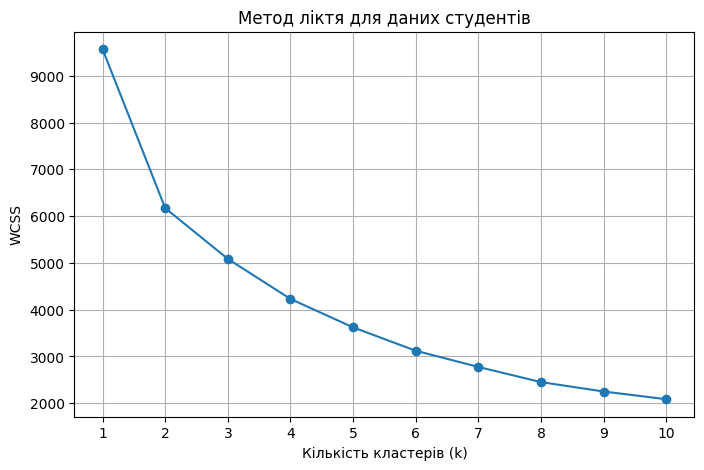

In [19]:
# Метод ліктя для чотирьох числових ознак студентів
student_cluster_features = ['Age', 'StudyTimeWeekly', 'Absences', 'GPA']
X_students_cluster = df[student_cluster_features].copy()

scaler_students = StandardScaler()
X_students_scaled = scaler_students.fit_transform(X_students_cluster)

wcss_students = []
student_k_values = range(1, 11)
for k in student_k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_students_scaled)
    wcss_students.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(list(student_k_values), wcss_students, marker='o')
plt.title('Метод ліктя для даних студентів')
plt.xlabel('Кількість кластерів (k)')
plt.ylabel('WCSS')
plt.xticks(list(student_k_values))
plt.grid(True)
plt.show()


### 2.15. Кластеризація даних студентів: метод силуетів

**Метод силуетів для студентів.** Для тих самих чотирьох ознак побудуйте графік коефіцієнта силуета для 2–10 кластерів.

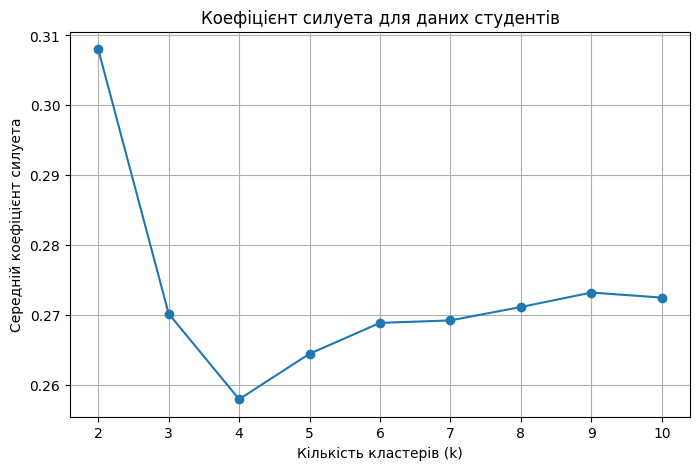

Найкраще значення силуета: k=2, score=0.3080


In [20]:
# Метод силуетів для чотирьох числових ознак студентів
student_silhouette_values = []
student_silhouette_k = range(2, 11)
for k in student_silhouette_k:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_students_scaled)
    student_silhouette_values.append(silhouette_score(X_students_scaled, labels))

plt.figure(figsize=(8, 5))
plt.plot(list(student_silhouette_k), student_silhouette_values, marker='o')
plt.title('Коефіцієнт силуета для даних студентів')
plt.xlabel('Кількість кластерів (k)')
plt.ylabel('Середній коефіцієнт силуета')
plt.xticks(list(student_silhouette_k))
plt.grid(True)
plt.show()

best_student_silhouette_k = list(student_silhouette_k)[int(max(range(len(student_silhouette_values)), key=student_silhouette_values.__getitem__))]
print(f"Найкраще значення силуета: k={best_student_silhouette_k}, score={max(student_silhouette_values):.4f}")


### 2.16. Додатковий підхід: PCA та автоматичне визначення точки ліктя

Тут використовується **інший набір ознак**: усі стовпці, крім `StudentID` та `GradeClass`. Після PCA кластеризацію проведемо за вибраними головними компонентами.

**Установлення додаткових пакетів.** За потреби встановіть `kneed` і `yellowbrick` у середовищі ноутбука.

In [21]:
# Установлення пакетів для автоматичного визначення точки ліктя
%pip -q install kneed yellowbrick


**Імпорт PCA і KneeLocator.** Імпортуйте `PCA`, `KneeLocator` та `numpy`.

In [22]:
# Імпорт PCA, KneeLocator та numpy
import numpy as np
from sklearn.decomposition import PCA
from kneed import KneeLocator


**Підготовка всіх ознак.** Приберіть `StudentID` і `GradeClass`, залишивши ознаки для PCA.

In [23]:
# Підготовка всіх ознак, крім StudentID та GradeClass
X_pca = df.drop(columns=['StudentID', 'GradeClass']).select_dtypes(include=[np.number]).copy()
print("Кількість ознак для PCA:", X_pca.shape[1])
print("Використані ознаки:", X_pca.columns.tolist())


Кількість ознак для PCA: 13
Використані ознаки: ['Age', 'Gender', 'Ethnicity', 'ParentalEducation', 'StudyTimeWeekly', 'Absences', 'Tutoring', 'ParentalSupport', 'Extracurricular', 'Sports', 'Music', 'Volunteering', 'GPA']


**Модель PCA.** Стандартизуйте ознаки, навчіть PCA та знайдіть частку поясненої дисперсії кожної компоненти.

In [24]:
# Стандартизація ознак та навчання PCA
scaler_pca = StandardScaler()
X_pca_scaled = scaler_pca.fit_transform(X_pca)

pca = PCA()
X_pca_all = pca.fit_transform(X_pca_scaled)
explained_variance_ratio = pca.explained_variance_ratio_

print("Частка поясненої дисперсії кожної компоненти:")
for i, ratio in enumerate(explained_variance_ratio, start=1):
    print(f"Компонента {i}: {ratio:.4f} ({ratio*100:.2f}%)")


Частка поясненої дисперсії кожної компоненти:
Компонента 1: 0.1525 (15.25%)
Компонента 2: 0.0861 (8.61%)
Компонента 3: 0.0827 (8.27%)
Компонента 4: 0.0807 (8.07%)
Компонента 5: 0.0786 (7.86%)
Компонента 6: 0.0779 (7.79%)
Компонента 7: 0.0763 (7.63%)
Компонента 8: 0.0760 (7.60%)
Компонента 9: 0.0744 (7.44%)
Компонента 10: 0.0738 (7.38%)
Компонента 11: 0.0717 (7.17%)
Компонента 12: 0.0675 (6.75%)
Компонента 13: 0.0018 (0.18%)


**Визначення кількості компонент.** Застосуйте `KneeLocator` до часток поясненої дисперсії. У підписі графіка вказуйте номер компоненти без додавання одиниці.

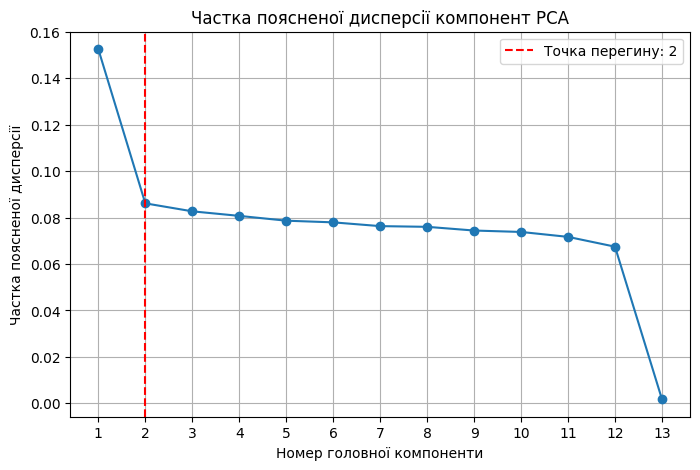

Обрана кількість компонент: 2


In [25]:
# Визначення точки перегину за частками поясненої дисперсії
component_numbers = np.arange(1, len(explained_variance_ratio) + 1)
knee_locator_pca = KneeLocator(
    component_numbers,
    explained_variance_ratio,
    curve='convex',
    direction='decreasing'
)
pca_knee = knee_locator_pca.knee

plt.figure(figsize=(8, 5))
plt.plot(component_numbers, explained_variance_ratio, marker='o')
if pca_knee is not None:
    plt.axvline(pca_knee, color='red', linestyle='--', label=f'Точка перегину: {pca_knee}')
    plt.legend()
plt.title('Частка поясненої дисперсії компонент PCA')
plt.xlabel('Номер головної компоненти')
plt.ylabel('Частка поясненої дисперсії')
plt.xticks(component_numbers)
plt.grid(True)
plt.show()

if pca_knee is None:
    # Якщо KneeLocator не виявив чіткої точки перегину, беремо мінімум компонент,
    # що разом пояснюють не менше 90% дисперсії.
    pca_n_components = int(np.argmax(np.cumsum(explained_variance_ratio) >= 0.90) + 1)
    print("Чітку точку перегину не знайдено; використано критерій 90% кумулятивної дисперсії.")
else:
    pca_n_components = int(pca_knee)
print("Обрана кількість компонент:", pca_n_components)


**Кумулятивна пояснена дисперсія.** На горизонтальній осі має бути **кількість головних компонент** (1, 2, 3, ...), тому індекс масиву для `n_components` дорівнює `n_components - 1`.

**Кумулятивна дисперсія та перетворення PCA.** Побудуйте графік кумулятивної дисперсії та позначте знайдену кількість компонент. Виведіть фактичну частку дисперсії. Перетворіть ознаки через PCA для наступного етапу.

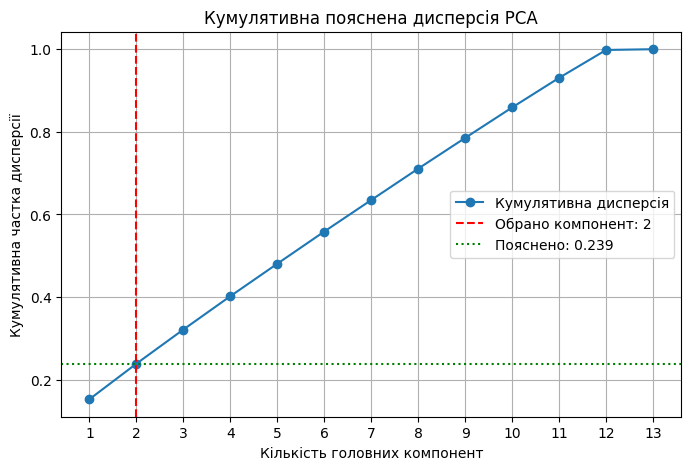

Обрано компонент: 2
Фактична кумулятивна частка дисперсії: 0.2386 (23.86%)
Розмір даних після PCA: (2392, 2)


In [26]:
# Кумулятивна пояснена дисперсія та перетворення PCA
cumulative_variance = np.cumsum(explained_variance_ratio)
selected_cumulative_variance = cumulative_variance[pca_n_components - 1]

plt.figure(figsize=(8, 5))
plt.plot(component_numbers, cumulative_variance, marker='o', label='Кумулятивна дисперсія')
plt.axvline(pca_n_components, color='red', linestyle='--',
            label=f'Обрано компонент: {pca_n_components}')
plt.axhline(selected_cumulative_variance, color='green', linestyle=':',
            label=f'Пояснено: {selected_cumulative_variance:.3f}')
plt.title('Кумулятивна пояснена дисперсія PCA')
plt.xlabel('Кількість головних компонент')
plt.ylabel('Кумулятивна частка дисперсії')
plt.xticks(component_numbers)
plt.grid(True)
plt.legend()
plt.show()

pca_selected = PCA(n_components=pca_n_components)
X_students_pca = pca_selected.fit_transform(X_pca_scaled)
print(f"Обрано компонент: {pca_n_components}")
print(f"Фактична кумулятивна частка дисперсії: {selected_cumulative_variance:.4f} ({selected_cumulative_variance*100:.2f}%)")
print("Розмір даних після PCA:", X_students_pca.shape)


Зауваження: кумулятивна пояснена дисперсія — це **частка дисперсії**, а не відсоток «інформативності» даних. Значення потрібно брати з розрахунку, а не задавати наперед (наприклад, 32%).

**Імпорт KElbowVisualizer.** Імпортуйте `KElbowVisualizer` із `yellowbrick.cluster`.

In [27]:
# Імпорт KElbowVisualizer
from yellowbrick.cluster import KElbowVisualizer


**Метод ліктя після PCA.** Побудуйте графік `KElbowVisualizer` для K-Means. Для узгодженості з попереднім етапом використайте **дані після PCA**.

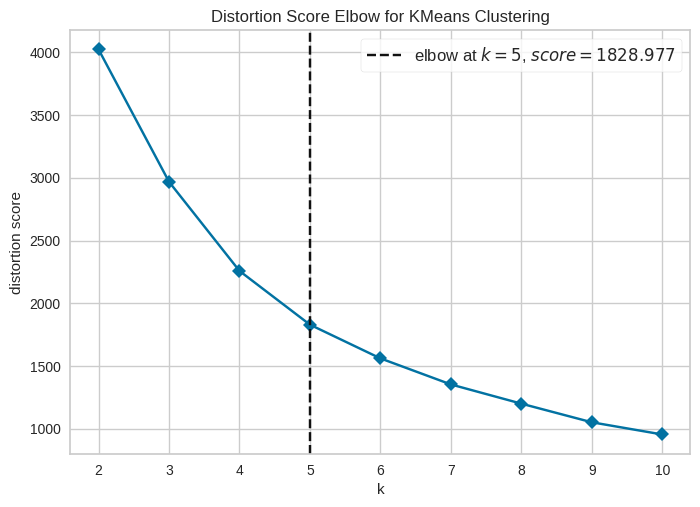

Оптимальна кількість кластерів за KElbowVisualizer: 5


In [28]:
# Метод ліктя після PCA на даних, перетворених PCA
kmeans_pca = KMeans(random_state=42, n_init=10)
elbow_visualizer = KElbowVisualizer(kmeans_pca, k=(2, 11), metric='distortion', timings=False)
elbow_visualizer.fit(X_students_pca)
elbow_visualizer.show()
print("Оптимальна кількість кластерів за KElbowVisualizer:", elbow_visualizer.elbow_value_)


## Висновки

Порівняйте результати різних способів визначення кількості кластерів та сформулюйте короткі висновки. Для завдання 2 окремо поясніть різницю між класифікацією за `GradeClass` і кластеризацією без цільової змінної. Зазначте, скільки головних компонент обрано та яку частку дисперсії вони пояснюють.

**Висновок**

У першому завданні було використано набір Iris: дані стандартизовано, після чого кількість кластерів досліджено методом ліктя та коефіцієнтом силуета. Для фінальної моделі залишено два кластери відповідно до умови завдання. Графік відображає результат за двома першими ознаками, хоча сама кластеризація виконується за трьома ознаками.

У другому завданні спочатку виконано класифікацію, де `GradeClass` є відомою цільовою змінною, а моделі навчаються передбачати її значення. Під час кластеризації `GradeClass` не використовується: алгоритм групує студентів за схожістю числових характеристик без готових міток класів. PCA застосовано для перетворення набору ознак у простір головних компонент і зменшення розмірності зі збереженням основної частини дисперсії.

In [29]:
# Формування підсумкового висновку з фактичними результатами запуску
print("ПІДСУМКОВИЙ ВИСНОВОК")
print(
    f"Під час лабораторної роботи я дослідив кластеризацію набору Iris за трьома ознаками. "
    f"Для Iris найбільший коефіцієнт силуета отримано при k={best_silhouette_k_iris} "
    f"(значення {max(silhouette_values_iris):.4f}), що підтримує вибір двох кластерів. "
    f"У завданні з даними студентів найкращою за CV accuracy виявилася модель {best_model_name} "
    f"із середньою точністю {max(rf_grid.best_score_, logreg_grid.best_score_, svm_grid.best_score_):.4f}; "
    f"її точність на тестовій вибірці становить "
    f"{accuracy_score(y_test, best_model.predict(X_test_scaled)):.4f}. "
    f"Кластеризацію студентів виконано за ознаками Age, StudyTimeWeekly, Absences та GPA без використання GradeClass. "
    f"Після PCA залишено {pca_n_components} компонент, які пояснюють "
    f"{selected_cumulative_variance*100:.2f}% загальної дисперсії. "
    f"Отже, класифікація дає змогу передбачати відомі класи, а кластеризація самостійно об’єднує схожі записи; PCA допомагає зменшити кількість ознак."
)


ПІДСУМКОВИЙ ВИСНОВОК
Під час лабораторної роботи я дослідив кластеризацію набору Iris за трьома ознаками. Для Iris найбільший коефіцієнт силуета отримано при k=2 (значення 0.5525), що підтримує вибір двох кластерів. У завданні з даними студентів найкращою за CV accuracy виявилася модель Random Forest із середньою точністю 0.9211; її точність на тестовій вибірці становить 0.9102. Кластеризацію студентів виконано за ознаками Age, StudyTimeWeekly, Absences та GPA без використання GradeClass. Після PCA залишено 2 компонент, які пояснюють 23.86% загальної дисперсії. Отже, класифікація дає змогу передбачати відомі класи, а кластеризація самостійно об’єднує схожі записи; PCA допомагає зменшити кількість ознак.
